In [11]:
!pip install -q keras-tuner


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


RNN   | Best Acc: 58.20% | Params: 328321 | Time: 16.83s | HP: {'emb': 64, 'drop': 0.4, 'units': 64, 'lr': 0.01}
LSTM  | Best Acc: 76.50% | Params: 332449 | Time: 17.73s | HP: {'emb': 64, 'drop': 0.4, 'units': 32, 'lr': 0.001}
GRU   | Best Acc: 76.40% | Params: 329441 | Time: 22.02s | HP: {'emb': 64, 'drop': 0.4, 'units': 32, 'lr': 0.001}


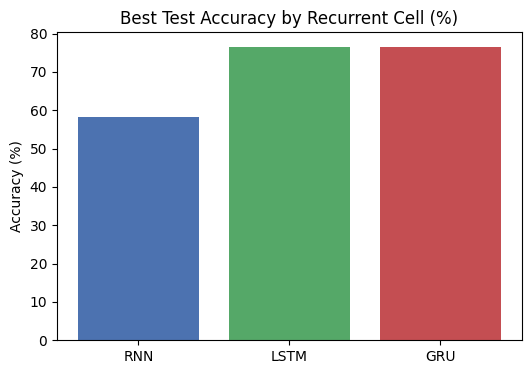

In [12]:
# !pip install -q keras-tuner
import time
import keras_tuner as kt
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

vocab_size, max_len = 5000, 100
(x_tr, y_tr), (x_te, y_te) = tf.keras.datasets.imdb.load_data(num_words=vocab_size)
x_tr = tf.keras.preprocessing.sequence.pad_sequences(x_tr[:3000], maxlen=max_len)
y_tr = y_tr[:3000]
x_te = tf.keras.preprocessing.sequence.pad_sequences(x_te[:1000], maxlen=max_len)
y_te = y_te[:1000]

cell_map = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}
best_accs, best_times = [], []

for name, cls in cell_map.items():
    def build_fn(hp):
        m = models.Sequential([
            layers.Embedding(vocab_size, hp.Choice("emb", [32, 64])),
            layers.Dropout(hp.Choice("drop", [0.2, 0.4])),
            cls(hp.Choice("units", [32, 64])),
            layers.Dense(1, activation="sigmoid")
        ])
        m.compile(optimizer=tf.keras.optimizers.Adam(hp.Choice("lr", [1e-2, 1e-3])),
                  loss="binary_crossentropy", metrics=["accuracy"])
        return m

    tuner = kt.RandomSearch(build_fn, objective="val_accuracy", max_trials=2,
                            directory="kt_dir", project_name=f"exp18_{name}", overwrite=True)
    t0 = time.time()
    tuner.search(x_tr, y_tr, epochs=2, validation_split=0.2, verbose=0)
    dt = time.time() - t0
    best_m = tuner.get_best_models(1)[0]
    _, acc = best_m.evaluate(x_te, y_te, verbose=0)
    best_accs.append(acc * 100); best_times.append(dt)
    print(f"{name:5s} | Best Acc: {acc*100:.2f}% | Params: {best_m.count_params()} | Time: {dt:.2f}s | HP: {tuner.get_best_hyperparameters(1)[0].values}")

plt.figure(figsize=(6, 4))
plt.bar(list(cell_map.keys()), best_accs, color=["#4c72b0", "#55a868", "#c44e52"])
plt.title("Best Test Accuracy by Recurrent Cell (%)"); plt.ylabel("Accuracy (%)"); plt.show()